# 1. Introduction

##### The objective of this notebook is to get familiar with commonly used ML libraries such as pandas or numpy. We will use the scikit-learn package to import the Iris dataset and we will evaluate various models.

## 2. Data exploration: statistics and visualization of data

In [2]:
from sklearn.datasets import load_iris
import pandas as pd

#Load the dataset
iris = load_iris(as_frame=True)

#Create a table with the data
df = iris.frame.copy()

#Add the name of the species for understabilty
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

#Show the first rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print("Dimensions of the dataset \n")
print(df.shape)

print("Available species \n")
print(iris.target_names)

print("Number of flowers per species \n")
print(df["species"].value_counts())

Dimensions of the dataset 

(150, 6)
Available species 

['setosa' 'versicolor' 'virginica']
Number of flowers per species 

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
df[iris.feature_names].describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:
df.groupby("species")[iris.feature_names].mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


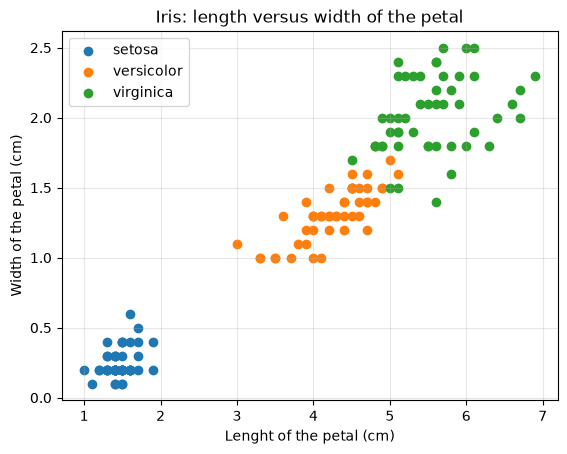

In [6]:
import matplotlib.pyplot as plt

for species in iris.target_names:
    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species
    )
plt.xlabel("Lenght of the petal (cm)")
plt.ylabel("Width of the petal (cm)")
plt.title("Iris: length versus width of the petal")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. Baseline model: KNN

In [7]:
#Input variables: the four measurements of each flower
X = df[iris.feature_names]

#Objective variable: The species of each flower
y = df["target"]

print("Dimensions of X:", X.shape)
print("Dimensions of y:", y.shape)


Dimensions of X: (150, 4)
Dimensions of y: (150,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [9]:
from sklearn.neighbors import KNeighborsClassifier

#Create the model with 5 neighbors
knn = KNeighborsClassifier(n_neighbors=5)

#Train the model
knn.fit(X_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [10]:
from sklearn.metrics import accuracy_score

#Predict the species of the flowers in the test set
y_pred = knn.predict(X_test)

#Calculate the proportion of valid predictions
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy in test: {accuracy:.2%}")

Accuracy in test: 100.00%


In [11]:
results = pd.DataFrame({
    "Real": iris.target_names[y_test],
    "Prediction": iris.target_names[y_pred]
})

results.head(10)

,Real,Prediction
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


In [12]:
print("Incorrect predictions:", (y_test != y_pred).sum())

Incorrect predictions: 0


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")
confusion_mat = confusion_matrix(y_test, y_pred)

print(f"precision: {precision:.2%}")
print(f"recall: {recall:.2%}")
print(f"f1 score: {f1:.2%}")
print(f"confusion matrix: {confusion_mat}")

precision: 100.00%
recall: 100.00%
f1 score: 100.00%
confusion matrix: [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


## 4. 5-fold cross-validation

In [14]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(knn, X, y, cv=5, scoring="accuracy")

print("Accuracy for each fold: ", scores)
print(f"Mean accuracy: {scores.mean()}")
print(f"Standard deviation: {scores.std()}")

Accuracy for each fold:  [0.96666667 1.         0.93333333 0.96666667 1.        ]
Mean accuracy: 0.9733333333333334
Standard deviation: 0.02494438257849294


## 5. Model comparison

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

import pandas as pd

models = {
    "KNN": make_pipeline(
        StandardScaler(),
        knn
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": make_pipeline(
        StandardScaler(),
        LinearSVC(random_state=42, max_iter=10000)
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=10000)
    )
}

results1 = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    results1.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std Accuracy": scores.std()
    })

results1_df = pd.DataFrame(results1)

skf = StratifiedKFold(n_splits = 5, shuffle=True, random_state = 42)

results2 = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=skf,
        scoring="accuracy"
    )

    results2.append({
        "Model": name,
        "Mean Accuracy": scores.mean(),
        "Std Accuracy": scores.std()
    })

results2_df = pd.DataFrame(results2)
results2_df



,Model,Mean Accuracy,Std Accuracy
0,KNN,0.973333,0.024944
1,Decision Tree,0.953333,0.033993
2,SVM,0.926667,0.053333
3,Logistic Regression,0.953333,0.045216


#### Let's plot the results

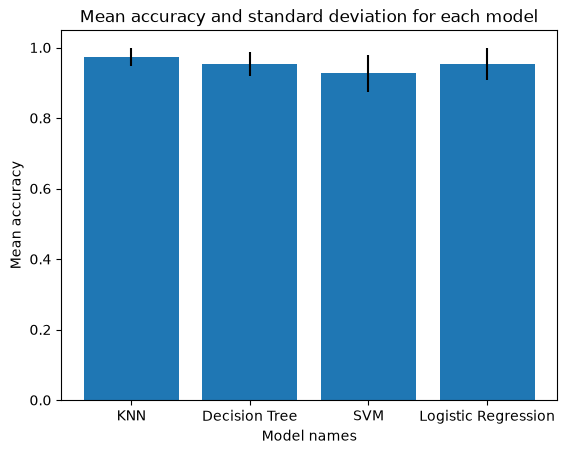

In [26]:
import importlib
import matplotlib.pyplot as plt

# importlib.reload(plt)

plt.bar(x = results2_df["Model"], height = results2_df["Mean Accuracy"], yerr = results2_df["Std Accuracy"])

plt.xlabel("Model names")
plt.ylabel("Mean accuracy")
plt.title("Mean accuracy and standard deviation for each model")
plt.show()

